# Fase 4 — Modelagem

O objetivo desta fase é aplicar as técnicas, definir o desenho de teste e iterar parâmetros até encontrar um modelo que atenda às metas técnicas da Fase 1. Checklist do guia:

1. Selecionar as técnicas
2. Gerar o desenho de teste (partição em treino e teste)
3. Construir e iterar os modelos
4. Fazer a avaliação técnica (estatística)

A avaliação pelos critérios de **negócio** fica para a Fase 5. O conjunto de teste é separado aqui e **não é usado** em nenhuma decisão deste notebook.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import recall_score, precision_score

RAIZ = Path("..").resolve()
sys.path.append(str(RAIZ))
from src.negocio import PREMISSAS, retorno_campanha

sns.set_theme(style="whitegrid")
SEMENTE = 42
COR = "#2f6fab"

df = pd.read_csv(RAIZ / "data" / "processed" / "telco_churn_preparado.csv")
print(df.shape)

(7043, 23)


## 1. Seleção das técnicas

O problema é de classificação binária em dados tabulares, com cerca de 7 mil linhas. Foram escolhidas técnicas de complexidade crescente:

| Técnica | Por que foi incluída |
|---|---|
| Classificador ingênuo (`DummyClassifier`) | Linha de base: qualquer modelo útil precisa superá-lo |
| Regressão logística | Simples, rápida e interpretável (cada atributo tem um coeficiente) |
| Árvore de decisão | Gera regras legíveis; captura relações não lineares |
| Random Forest | Conjunto de árvores; mais estável do que uma árvore isolada |
| Gradient Boosting | Costuma ter o melhor desempenho em dados tabulares |

**Regra de escolha, definida antes de ver os resultados:** vence o modelo com a maior ROC-AUC média na validação cruzada. Se a diferença para um modelo mais simples for menor que 0,005, fica o mais simples, porque é mais fácil de explicar ao negócio (critério CN3) e de manter.

## 2. Desenho de teste

- **Teste:** 20% dos clientes, separados por sorteio estratificado (mesma proporção de cancelamentos) e guardados para a Fase 5.
- **Treino:** os 80% restantes. Toda comparação e todo ajuste usam **validação cruzada estratificada com 5 partes** dentro do treino.
- **Métricas:** ROC-AUC (capacidade de ordenar os clientes por risco, independente do limiar), precisão média, recall, precisão e F1 da classe "cancelou".
- **Semente aleatória:** 42, para que os resultados possam ser reproduzidos.

In [2]:
treino, teste = train_test_split(df, test_size=0.20, stratify=df["Churn"], random_state=SEMENTE)

treino.to_csv(RAIZ / "data" / "processed" / "treino.csv", index=False)
teste.to_csv(RAIZ / "data" / "processed" / "teste.csv", index=False)

print(f"Treino: {len(treino):,} clientes, {treino['Churn'].mean():.1%} de cancelamentos")
print(f"Teste:  {len(teste):,} clientes, {teste['Churn'].mean():.1%} de cancelamentos")

X_treino = treino.drop(columns=["customerID", "Churn"])
y_treino = treino["Churn"]

numericas, categoricas = X_treino.select_dtypes("number").columns.tolist(), X_treino.select_dtypes(exclude="number").columns.tolist()
print("\nAtributos numéricos:  ", numericas)
print("Atributos categóricos:", categoricas)

Treino: 5,634 clientes, 26.5% de cancelamentos
Teste:  1,409 clientes, 26.5% de cancelamentos

Atributos numéricos:   ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServicosAdicionais']
Atributos categóricos: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'FaixaTenure']


### Pré-processamento dentro do pipeline

A padronização dos atributos numéricos e a codificação one-hot das categorias ficam dentro de um `Pipeline`. Assim, em cada rodada da validação cruzada elas são ajustadas apenas com a parte de treino, sem vazamento de informação.

In [3]:
def colunas_por_tipo(X):
    numericas = X.select_dtypes("number").columns.tolist()
    categoricas = [c for c in X.columns if c not in numericas]
    return numericas, categoricas

def criar_pipeline(modelo, X):
    numericas, categoricas = colunas_por_tipo(X)
    preprocessamento = ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categoricas),
    ])
    return Pipeline([("preprocessamento", preprocessamento), ("modelo", modelo)])

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
METRICAS = ["roc_auc", "average_precision", "recall", "precision", "f1"]

## 3. Construção dos modelos

### 3.1 Primeira rodada: parâmetros padrão

In [4]:
candidatos = {
    "Classificador ingênuo": DummyClassifier(strategy="prior"),
    "Regressão logística": LogisticRegression(max_iter=1000),
    "Árvore de decisão": DecisionTreeClassifier(max_depth=5, random_state=SEMENTE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEMENTE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEMENTE),
}

linhas = []
for nome, modelo in candidatos.items():
    r = cross_validate(criar_pipeline(modelo, X_treino), X_treino, y_treino, cv=validacao, scoring=METRICAS)
    linha = {"modelo": nome}
    for m in METRICAS:
        linha[m] = r[f"test_{m}"].mean()
    linha["roc_auc_desvio"] = r["test_roc_auc"].std()
    linhas.append(linha)

comparacao = pd.DataFrame(linhas).set_index("modelo").round(4)
comparacao

,roc_auc,average_precision,recall,precision,f1,roc_auc_desvio
modelo,,,,,,
Classificador ingênuo,0.5000,0.2654,0.0000,0.0000,0.0000,0.0000
Regressão logística,0.8464,0.6653,0.5358,0.6681,0.5939,0.0116
Árvore de decisão,0.8288,0.6121,0.5398,0.6176,0.5744,0.0110
Random Forest,0.8453,0.6590,0.4963,0.6717,0.5707,0.0110
Gradient Boosting,0.8476,0.6650,0.5224,0.6635,0.5842,0.0123


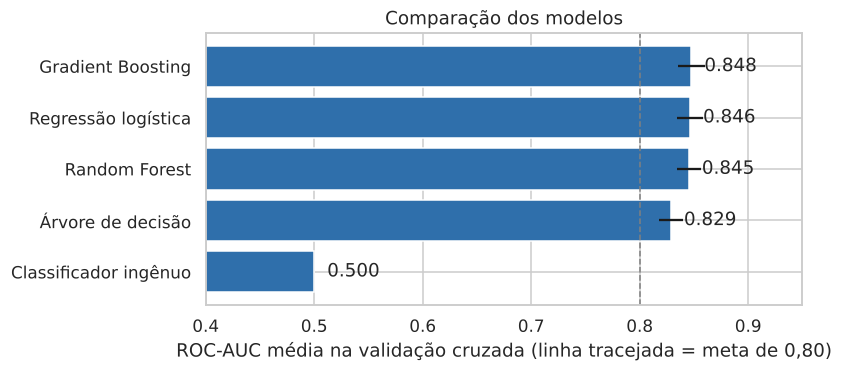

In [5]:
ordenado = comparacao["roc_auc"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(ordenado.index, ordenado.values, xerr=comparacao.loc[ordenado.index, "roc_auc_desvio"], color=COR)
for i, v in enumerate(ordenado.values):
    ax.text(v + 0.012, i, f"{v:.3f}", va="center")
ax.axvline(0.80, color="gray", linestyle="--", linewidth=1)
ax.set_xlim(0.4, 0.95)
ax.set_xlabel("ROC-AUC média na validação cruzada (linha tracejada = meta de 0,80)")
ax.set_title("Comparação dos modelos")
plt.show()

Todos os modelos superam com folga a linha de base (0,50) e a meta de 0,80. Regressão logística (0,846), Gradient Boosting (0,848) e Random Forest (0,845) estão empatados na prática: a diferença entre eles é menor do que a variação entre as partes da validação cruzada (cerca de 0,011). A árvore de decisão isolada fica um pouco atrás (0,829).

No limiar padrão de 0,50, porém, todos encontram apenas cerca de metade dos cancelamentos (recall entre 0,50 e 0,54), abaixo da meta de 0,70. O problema não está na capacidade de ordenar os clientes por risco, e sim no ponto de corte, que é tratado na seção 3.5.

### 3.2 Iteração 1: ajuste de hiperparâmetros

Os dois melhores modelos da primeira rodada passam por uma busca em grade (`GridSearchCV`), usando a mesma validação cruzada.

In [6]:
def ajustar_modelos(X):
    """Busca em grade para a regressão logística e o Gradient Boosting com os atributos de X."""
    rl = GridSearchCV(
        criar_pipeline(LogisticRegression(max_iter=3000), X),
        {"modelo__C": [0.01, 0.1, 1, 10, 100]},
        cv=validacao, scoring="roc_auc",
    ).fit(X, y_treino)
    gb = GridSearchCV(
        criar_pipeline(GradientBoostingClassifier(random_state=SEMENTE), X),
        {"modelo__n_estimators": [100, 200], "modelo__learning_rate": [0.05, 0.1], "modelo__max_depth": [2, 3]},
        cv=validacao, scoring="roc_auc", n_jobs=-1,
    ).fit(X, y_treino)
    return rl, gb

busca_rl, busca_gb = ajustar_modelos(X_treino)

pd.set_option("display.max_colwidth", 120)
ajuste = pd.DataFrame({
    "modelo": ["Regressão logística", "Gradient Boosting"],
    "roc_auc_padrao": [comparacao.loc["Regressão logística", "roc_auc"], comparacao.loc["Gradient Boosting", "roc_auc"]],
    "roc_auc_ajustado": [round(busca_rl.best_score_, 4), round(busca_gb.best_score_, 4)],
    "melhores_parametros": [str(busca_rl.best_params_), str(busca_gb.best_params_)],
}).set_index("modelo")
ajuste

,roc_auc_padrao,roc_auc_ajustado,melhores_parametros
modelo,,,
Regressão logística,0.8464,0.8465,{'modelo__C': 10}
Gradient Boosting,0.8476,0.8490,"{'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__n_estimators': 100}"


O ajuste quase não altera o resultado: de 0,8464 para 0,8465 na regressão logística e de 0,8476 para 0,8490 no Gradient Boosting. O desempenho parece limitado pela informação disponível nos dados, e não pela configuração dos algoritmos.

### 3.3 Iteração 2: inspeção do modelo e retorno à Preparação

Antes de fechar o modelo, vale conferir se o que ele aprendeu é coerente com a Fase 2. A regressão logística permite isso pelos coeficientes: sinal positivo aumenta o risco de cancelamento, negativo reduz.

In [7]:
def coeficientes(pipeline):
    nomes = pipeline.named_steps["preprocessamento"].get_feature_names_out()
    return pd.Series(pipeline.named_steps["modelo"].coef_[0], index=[n.split("__", 1)[1] for n in nomes])

coef_antes = coeficientes(busca_rl.best_estimator_)
observar = ["MonthlyCharges", "NumServicosAdicionais", "InternetService_Fiber optic", "InternetService_No", "PhoneService_Yes", "tenure"]
coef_antes[observar].round(2).to_frame("coeficiente (todos os atributos)")

,coeficiente (todos os atributos)
MonthlyCharges,-1.60
NumServicosAdicionais,0.89
InternetService_Fiber optic,1.72
InternetService_No,-2.60
PhoneService_Yes,0.52
tenure,-1.28


Dois sinais contradizem o que foi visto na Fase 2:

- `MonthlyCharges` tem coeficiente **negativo** (−1,60), como se uma mensalidade mais alta reduzisse o risco. A hipótese H4 mostrou o contrário.
- `NumServicosAdicionais` tem coeficiente **positivo** (+0,89), contra a hipótese H5.

Além disso, os coeficientes de internet estão inflados (+1,72 para fibra e −2,60 para clientes sem internet). Esse padrão é típico de atributos redundantes: quando dois ou mais atributos carregam a mesma informação, o modelo pode dividir o peso entre eles de forma arbitrária, com sinais opostos que se compensam. A previsão continua boa, mas os coeficientes deixam de ser interpretáveis, o que compromete o critério CN3.

In [8]:
from sklearn.linear_model import LinearRegression

servicos = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
soma = (X_treino[servicos] == "Yes").sum(axis=1)
print("NumServicosAdicionais é a soma exata das seis colunas de serviço:", bool((soma == X_treino["NumServicosAdicionais"]).all()))

colunas_servico = ["PhoneService", "MultipleLines", "InternetService"] + servicos
dummies = pd.get_dummies(X_treino[colunas_servico], dtype=float)
r2 = LinearRegression().fit(dummies, X_treino["MonthlyCharges"]).score(dummies, X_treino["MonthlyCharges"])
print(f"Parcela da variação de MonthlyCharges explicada pelos serviços contratados (R²): {r2:.4f}")

NumServicosAdicionais é a soma exata das seis colunas de serviço: True
Parcela da variação de MonthlyCharges explicada pelos serviços contratados (R²): 0.9988


O diagnóstico confirma a redundância:

- `NumServicosAdicionais`, criado na Fase 3, é a soma exata de seis colunas que já estão no modelo.
- `MonthlyCharges` é determinada em 99,9% pelos serviços contratados. A mensalidade é, na prática, uma tabela de preços aplicada ao pacote do cliente.

**Retorno à Fase 3 (Preparação):** os dois atributos saem da lista de atributos do modelo. Eles continuam na base preparada, porque `MonthlyCharges` é necessária para a simulação financeira e `NumServicosAdicionais` é útil em análises descritivas. Os dois modelos são reajustados sem eles.

In [9]:
FORA_DO_MODELO = ["MonthlyCharges", "NumServicosAdicionais"]
X_reduzido = X_treino.drop(columns=FORA_DO_MODELO)

busca_rl2, busca_gb2 = ajustar_modelos(X_reduzido)

iteracao = pd.DataFrame({
    "todos os atributos": [busca_rl.best_score_, busca_gb.best_score_],
    "sem os 2 redundantes": [busca_rl2.best_score_, busca_gb2.best_score_],
}, index=["Regressão logística", "Gradient Boosting"]).round(4)
print("ROC-AUC média na validação cruzada:")
print(iteracao.to_string())
print("\nMelhores parâmetros:", busca_rl2.best_params_, "|", busca_gb2.best_params_)

coef_depois = coeficientes(busca_rl2.best_estimator_)
coef_depois[[c for c in observar if c in coef_depois.index]].round(2).to_frame("coeficiente (sem os redundantes)")

ROC-AUC média na validação cruzada:
                     todos os atributos  sem os 2 redundantes
Regressão logística              0.8465                0.8465
Gradient Boosting                0.8490                0.8493

Melhores parâmetros: {'modelo__C': 1} | {'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__n_estimators': 100}


,coeficiente (sem os redundantes)
InternetService_Fiber optic,0.58
InternetService_No,-1.09
PhoneService_Yes,-0.53
tenure,-1.17


O desempenho não mudou (0,8465 na regressão logística; 0,8490 → 0,8493 no Gradient Boosting), o que confirma que os dois atributos não traziam informação nova. Os coeficientes passaram a ter tamanhos moderados e sinais coerentes com a Fase 2: fibra aumenta o risco (+0,58), não ter internet reduz (−1,09) e o tempo de casa reduz (−1,17). O melhor valor de `C` caiu de 10 para 1, ou seja, o modelo passou a preferir mais regularização.

O modelo ficou mais simples (19 atributos em vez de 21) e voltou a ser explicável, sem perda de desempenho.

### 3.4 Escolha do modelo

In [10]:
# Aplicação da regra de escolha definida na seção 1
diferenca = busca_gb2.best_score_ - busca_rl2.best_score_
if diferenca >= 0.005:
    nome_final, busca_final = "Gradient Boosting", busca_gb2
else:
    nome_final, busca_final = "Regressão logística", busca_rl2

modelo_final = busca_final.best_estimator_
X_treino = X_reduzido
numericas, categoricas = colunas_por_tipo(X_treino)
print(f"Diferença de ROC-AUC (Gradient Boosting - Regressão logística): {diferenca:+.4f}")
print(f"Modelo escolhido: {nome_final} {busca_final.best_params_}")
print(f"Atributos usados: {len(numericas)} numéricos e {len(categoricas)} categóricos")

Diferença de ROC-AUC (Gradient Boosting - Regressão logística): +0.0028
Modelo escolhido: Regressão logística {'modelo__C': 1}
Atributos usados: 2 numéricos e 17 categóricos


O Gradient Boosting tem ROC-AUC de 0,8493 e a regressão logística de 0,8465. A diferença de 0,0028 é menor que o limite de 0,005 definido na seção 1, então fica a **regressão logística** (`C` = 1). O ganho do modelo mais complexo não compensa a perda de interpretabilidade.

### 3.5 Iteração 3: limiar de decisão

O modelo devolve uma probabilidade de cancelamento. Falta decidir **a partir de qual probabilidade o cliente entra na campanha**. O limiar padrão de 0,50 trata os dois tipos de erro como iguais, mas a Fase 1 mostrou que eles têm custos muito diferentes.

O limiar é escolhido pelo retorno líquido simulado da campanha, com as premissas da Fase 1. Para não usar o conjunto de teste, o cálculo é feito com as previsões "fora da amostra" da validação cruzada: cada cliente do treino é pontuado por um modelo que não o viu.

In [11]:
print("Premissas de negócio:", PREMISSAS)

prob_validacao = cross_val_predict(modelo_final, X_treino, y_treino, cv=validacao, method="predict_proba")[:, 1]

linhas = []
for limiar in np.round(np.arange(0.05, 0.96, 0.01), 2):
    contatar = prob_validacao >= limiar
    resultado = retorno_campanha(y_treino, contatar, treino["MonthlyCharges"])
    linhas.append({
        "limiar": limiar,
        "retorno_liquido": resultado["retorno_liquido"],
        "recall": recall_score(y_treino, contatar),
        "precisao": precision_score(y_treino, contatar) if contatar.any() else np.nan,
        "base_contatada": contatar.mean(),
    })
curva = pd.DataFrame(linhas).set_index("limiar")

LIMIAR = float(curva["retorno_liquido"].idxmax())
print(f"\nLimiar com maior retorno simulado: {LIMIAR:.2f}")
curva.loc[[LIMIAR, 0.50]].round(3)

Premissas de negócio: {'custo_contato': 50.0, 'taxa_sucesso': 0.3, 'meses_horizonte': 12}

Limiar com maior retorno simulado: 0.21


,retorno_liquido,recall,precisao,base_contatada
limiar,,,,
0.21,221584.74,0.852,0.483,0.468
0.50,174278.86,0.536,0.667,0.213


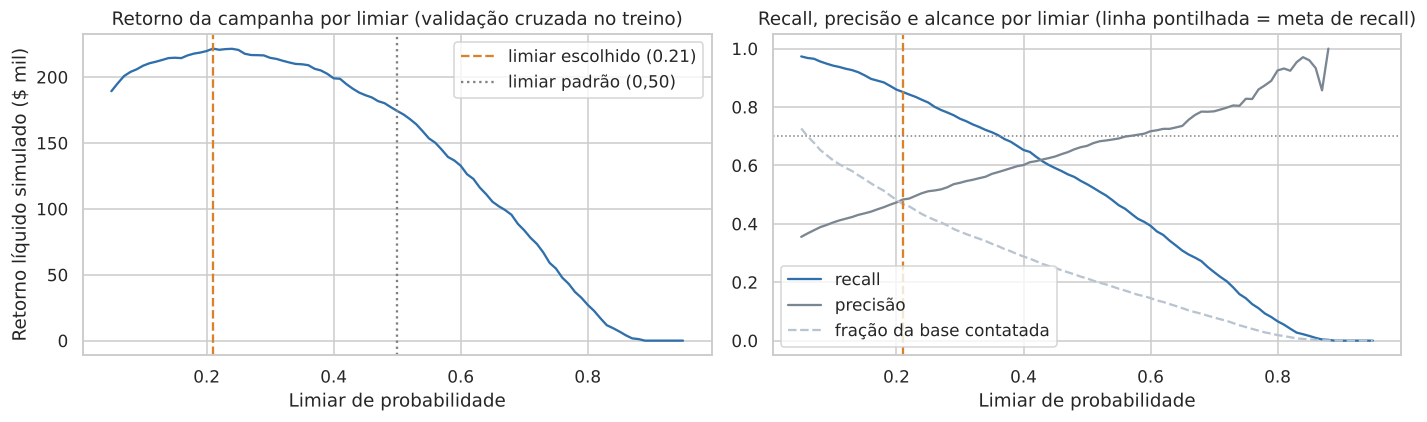

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(curva.index, curva["retorno_liquido"] / 1000, color=COR)
ax1.axvline(LIMIAR, color="#d9822b", linestyle="--", label=f"limiar escolhido ({LIMIAR:.2f})")
ax1.axvline(0.50, color="gray", linestyle=":", label="limiar padrão (0,50)")
ax1.set_xlabel("Limiar de probabilidade")
ax1.set_ylabel("Retorno líquido simulado ($ mil)")
ax1.set_title("Retorno da campanha por limiar (validação cruzada no treino)")
ax1.legend()

ax2.plot(curva.index, curva["recall"], color=COR, label="recall")
ax2.plot(curva.index, curva["precisao"], color="#7a8793", label="precisão")
ax2.plot(curva.index, curva["base_contatada"], color="#b8c4d0", linestyle="--", label="fração da base contatada")
ax2.axvline(LIMIAR, color="#d9822b", linestyle="--")
ax2.axhline(0.70, color="gray", linestyle=":", linewidth=1)
ax2.set_xlabel("Limiar de probabilidade")
ax2.set_title("Recall, precisão e alcance por limiar (linha pontilhada = meta de recall)")
ax2.legend()
plt.tight_layout()
plt.show()

O maior retorno simulado ocorre no limiar **0,21**. Na validação cruzada do treino (5.634 clientes), em comparação com o limiar padrão:

| | Limiar 0,21 | Limiar 0,50 |
|---|---|---|
| Recall | 85,2% | 53,6% |
| Precisão | 48,3% | 66,7% |
| Base contatada | 46,8% | 21,3% |
| Retorno líquido simulado | $ 221,6 mil | $ 174,3 mil |

O limiar baixo é consequência direta das premissas da Fase 1: como perder um cliente custa bem mais do que fazer um contato desnecessário, compensa contatar também clientes com probabilidade moderada de sair. **Se as premissas mudarem, o limiar precisa ser recalculado.**

## 4. Avaliação técnica

In [13]:
resumo = pd.Series({
    "modelo": nome_final,
    "parametros": str(busca_final.best_params_),
    "roc_auc_validacao": round(busca_final.best_score_, 4),
    "limiar": LIMIAR,
    "recall_validacao_no_limiar": round(curva.loc[LIMIAR, "recall"], 4),
    "precisao_validacao_no_limiar": round(curva.loc[LIMIAR, "precisao"], 4),
    "base_contatada_no_limiar": round(curva.loc[LIMIAR, "base_contatada"], 4),
}, name="valor")
resumo.to_frame()

,valor
modelo,Regressão logística
parametros,{'modelo__C': 1}
roc_auc_validacao,0.8465
limiar,0.21
recall_validacao_no_limiar,0.8515
precisao_validacao_no_limiar,0.4833
base_contatada_no_limiar,0.4675


In [14]:
# O melhor estimador da busca já foi reajustado com todo o conjunto de treino.
joblib.dump(modelo_final, RAIZ / "models" / "modelo_churn.joblib")

config = {
    "modelo": nome_final,
    "parametros": {k: v for k, v in busca_final.best_params_.items()},
    "limiar": LIMIAR,
    "roc_auc_validacao": round(float(busca_final.best_score_), 4),
    "recall_validacao": round(float(curva.loc[LIMIAR, "recall"]), 4),
    "atributos_fora_do_modelo": FORA_DO_MODELO,
    "atributos_numericos": numericas,
    "atributos_categoricos": categoricas,
    "premissas_negocio": PREMISSAS,
    "versao_scikit_learn": sklearn.__version__,
    "semente": SEMENTE,
}
with open(RAIZ / "models" / "config_modelo.json", "w", encoding="utf-8") as arquivo:
    json.dump(config, arquivo, ensure_ascii=False, indent=2)

print("Modelo salvo em models/modelo_churn.joblib")
print("Configuração salva em models/config_modelo.json")

Modelo salvo em models/modelo_churn.joblib
Configuração salva em models/config_modelo.json


## Resumo da fase

| Item | Resultado |
|---|---|
| Modelo escolhido | Regressão logística (`C` = 1), com padronização e one-hot encoding no pipeline |
| Atributos | 19 (2 numéricos e 17 categóricos) |
| ROC-AUC na validação cruzada | 0,8465 (meta CT1: ≥ 0,80) |
| Limiar de decisão | 0,21 |
| Recall na validação, no limiar | 0,85 (meta CT2: ≥ 0,70) |

**Iterações realizadas nesta fase**

1. Ajuste de hiperparâmetros, com ganho desprezível.
2. Retorno à Preparação: retirada de dois atributos redundantes que tornavam os coeficientes incoerentes.
3. Ajuste do limiar de decisão pelo retorno simulado da campanha, que levou o recall de 0,54 para 0,85.

As metas técnicas são atendidas na validação cruzada. A confirmação no conjunto de teste e a avaliação pelos critérios de negócio são feitas na Fase 5.